作为一个rler，训推diff对齐一直觉得是一个有门槛的事情【虽然但是，各种方法is/rs/sc等等能部分解决常见的训推diff-setting】，还是忍不住自己动手做了一遍对齐。

**本文的对齐方案基于vllm开源的训推diff-skill**，帮助实现了常见算子的训推diff对齐，但gdn效率上比较差，后续参考skyrl的IsoExec，进一步完成效率更高的对齐。全程许愿式编程。

目前，仅在qwen35-4b上验证且只针对单轮任务，未做moe的对齐（moe的对齐个人理解应该更简单一些）。

## GDN 两段式训推对齐方案（ISO mode）
- 方案名称： 
  - ISO（IsoExec-inspired two-pass computation）
- 目标：
  - Qwen3.5-4B-Base（GDN hybrid）训练、rollout prefill、rollout decode 三处的 GDN 层输出逐位相同，支持 TP、CP、CUDA graph，适用于 online RL 训练。
- 状态： 
  - 已完成实现与验证，默认关闭（需显式设置环境变量开启）。
- 验证口径： 
  - 沿用 vLLM train-inference-consistency skill（vllm-project/vllm#61551）及其本仓库再剪裁版 train-inference-diff0，详见第十节。
  
## 为什么需要两段式
原生 decode 与训练的差距（SGLANG_GDN_CPR=0）

标准 GDN 训练使用 chunk-parallel FLA kernel，它在每个 64-token chunk 内部先算出 h 和 v_new（fp32），但在写入输出之前将它们截断为 bf16，再用 bf16 的 h 和 v_new 做后续计算。SGLang 的 recurrent decode kernel 则全程用 fp32。这导致单层输出就有约 38% 的元素不同（bf16 vs fp32），逐层放大后：

In [1]:
from IPython.display import Image

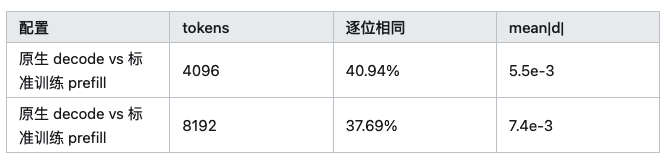

In [2]:
Image(filename='./Image/diff_01.png')

CPR 方案（SGLANG_GDN_CPR=1）让 rollout decode 也走 chunk kernel，能对齐训练，但 decode 吞吐比原生慢 2.1 倍。

两段式方案让训练和 decode 共用同一套 kernel，从而把 diff 降到 0，同时 decode 吞吐接近原生（1.055×）。

## 两段式计算的核心思路
训练、rollout prefill、rollout decode 三处都用两段式计算，分工如下：

  - Pass 1： 用 chunk-parallel FLA kernel 算出每 64 边界上的 fp32 状态（h 和 v）；
  - Pass 2： 每个 chunk 内部用 recurrent decode kernel 逐 token 算输出，从边界状态开始，全程 fp32。
  
训练和 decode 都执行完全相同的两段式：边界状态用同一个 chunk kernel 算出，chunk 内部用同一个 recurrent kernel 逐 token 生成输出。所以三处输出逐位相同。

### 与 IsoExec 的异同

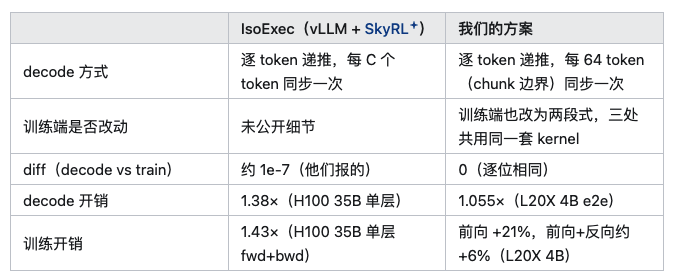

In [3]:
Image(filename='./Image/diff_02.png')

他们剩下的约 1e-7 我们推测出在训练端实现上（未验证），而我们的方案通过让训练端也走两段式，把三处统一到同一套 kernel，从而做到 0 残差。

## 正确性验证结果
### 验证条件
  - 模型： Qwen3.5-4B-Base（GDN hybrid，24 层）
  - 对比范围：
    - rollout decode（SGLang，graphed） vs rollout prefill（SGLang，graphed）
    - rollout prefill（SGLang） vs 训练 prefill（Megatron）
    - rollout decode（SGLang） vs 训练 prefill（Megatron）【主要指标】


  - CUDA graph： 全开（也单独测过 graph 关闭，结果相同）
  - 拓扑： TP1（单卡）、TP2（两卡）、n=7（graph 补到 8）、n=8

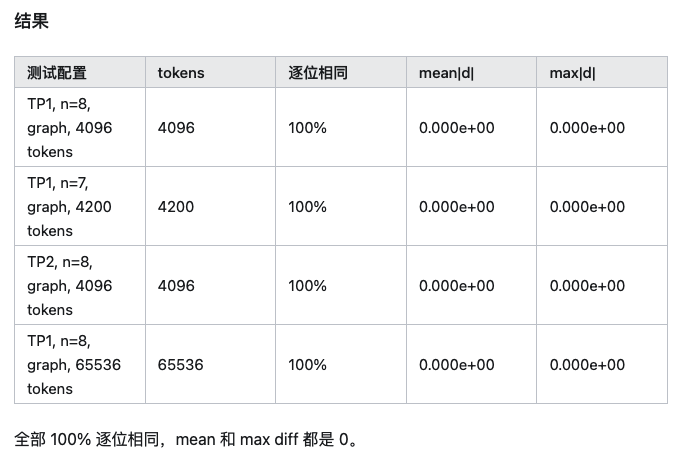

In [4]:
Image(filename='./Image/diff_03.png')

## 效率指标
### Decode 吞吐（端到端）
#### 测试配置：
Qwen3.5-4B-Base，128 个请求，每条 1024 token，并发 64，CUDA graph 开启，同一张卡上轮流跑（避免跨卡噪声）。

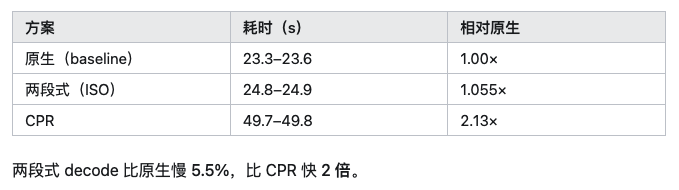

In [5]:
Image(filename='./Image/diff_04.png')

####  开销分解（单步，24 层，bs=64）
  - 原生每步约 22.2 ms（151 µs/layer）
  - 两段式每步约 23.2 ms（约 +1.0 ms）
    - GDN 递推 decode 本身：约 +0.45 ms
    - 边界同步（chunk-parallel pass 1）：约 +0.23 ms（每 64 token 触发一次）
    - 其他小 kernel 开销：约 +0.32 ms

### 训练前向吞吐（TP1 单卡）
测试配置： Qwen3.5-4B-Base，TP1，只前向（logprob），14.8k tokens（batch），median over 5 runs。

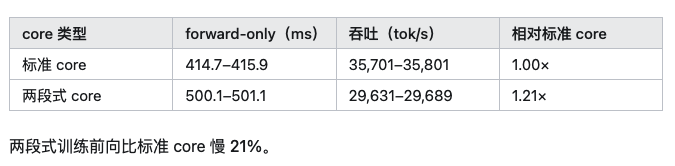

In [6]:
Image(filename='./Image/diff_05.png')

### 训练前向+反向吞吐（TP1 单卡）
测试配置： Qwen3.5-4B-Base，TP1，前向+反向（full backward），5.9k tokens（batch），median over 3 runs。

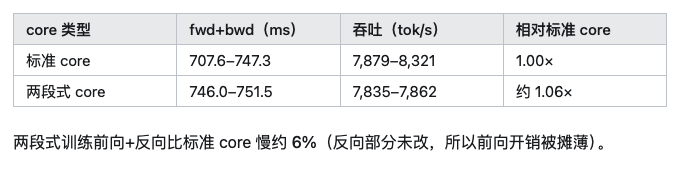

In [7]:
Image(filename='./Image/diff_06.png')

### 显存
每个请求槽多存：
  - 一份边界状态（每 64 token 一个，fp32 h 和 v）
  - 一个 chunk（64 token）的输入（x 和 ab）
4B 模型约 67 MB/槽。

### Prefill
Rollout 的 prefill 也走两段式 core（pass 1 + pass 2），GDN 部分本身约慢 4×。AIME 这种短 prompt 的任务影响很小，但长 prompt 多轮任务（如 agent 类任务）中 prefill 开销会更明显。

## Eval 对齐（step 0，Base 模型）
测试配置： Qwen3.5-4B-Base（未经训练的 Base 模型），AIME 24/25/26（30+30+30=90 题），每题 8 条样本，温度 1.0，最大输出 32k token，评分器 deepscaler，三臂同卡轮流运行（消除跨卡噪声）。

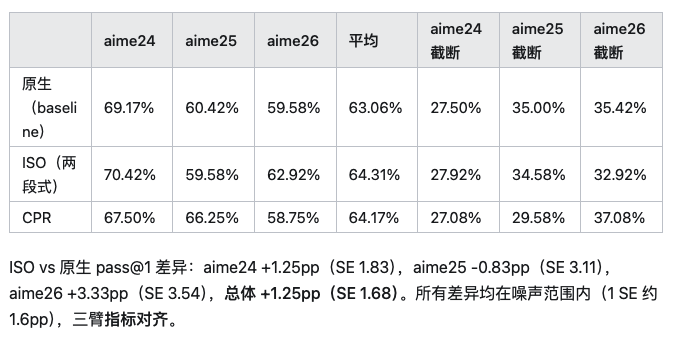

In [9]:
Image(filename='./Image/diff_07.png')

ISO vs 原生 pass@1 差异：aime24 +1.25pp（SE 1.83），aime25 -0.83pp（SE 3.11），aime26 +3.33pp（SE 3.54），总体 +1.25pp（SE 1.68）。所有差异均在噪声范围内（1 SE 约 1.6pp），三臂指标对齐。

### 吞吐（同一张卡，Base 模型，360 条请求 × 2 分片）：

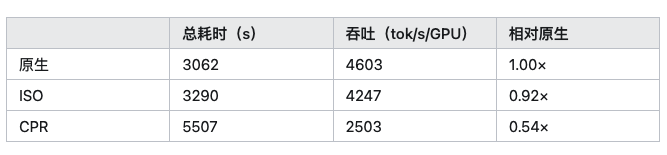

In [10]:
Image(filename='./Image/diff_08.png')

ISO 比原生慢 8%，比 CPR 快 1.7 倍。注意这里 ISO 的吞吐（0.92×）略低于第四节测得的 decode 端到端吞吐（0.95×），因为：
  - 第四节是纯 decode benchmark（并发 64，固定 1024 token/条）；
  - 这里是 eval（prompt prefill + decode 混合，且 prefill 也走两段式 core，GDN 部分约慢 4×）。
AIME 的 prompt 平均 198 token（最长 892），相对平均 19.5k 的输出只占约 1%，所以 prefill 开销几乎看不出来，eval 吞吐仍接近纯 decode 吞吐；长 prompt 多轮任务中 prefill 开销会更明显。

#### 两点口径说明：

  - eval 指标不可能「完全一致」。
    - diff=0 是 logprob 层面的性质；温度 1.0 采样下，哪怕 logprob 逐位相同，采到的 token 序列也会不同。所以 eval 只能验证「没有系统性偏移」，逐位相同由第三节的 logprob 对比负责。
  - 打分管线本身不引入抖动。 
    - 同一组 native 结果重跑一遍（表中未列的 nativeprev 对照臂），三个数据集逐题得分完全一致，paired diff +0.00%（SE 0.00%）。所以上表中的差异全部来自采样，而非评测管线。
    
与训练框架内 eval 的交叉验证： RL 训练脚本在 step 0 跑的 eval（第六节）走的是训练框架自己的 eval 通道，配置相同（n=8 / 32k / temp 1.0 / deepscaler）：

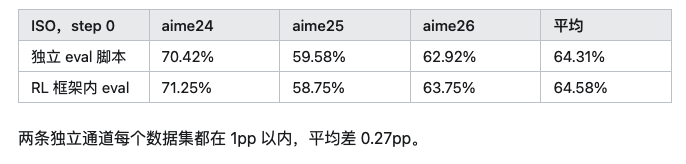

In [11]:
Image(filename='./Image/diff_09.png')

## Online RL 训练指标
### 训练配置

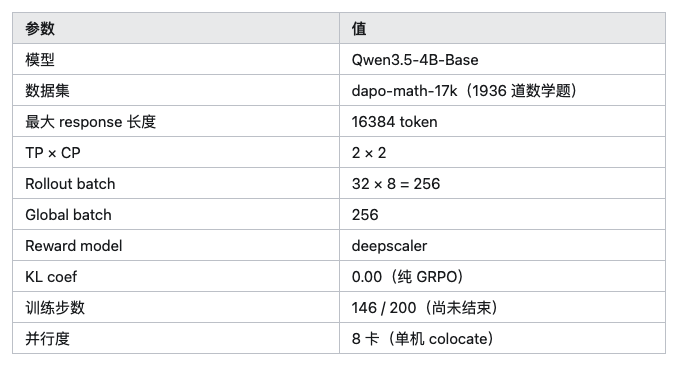

In [12]:
Image(filename='./Image/diff_10.png')

### 训练曲线

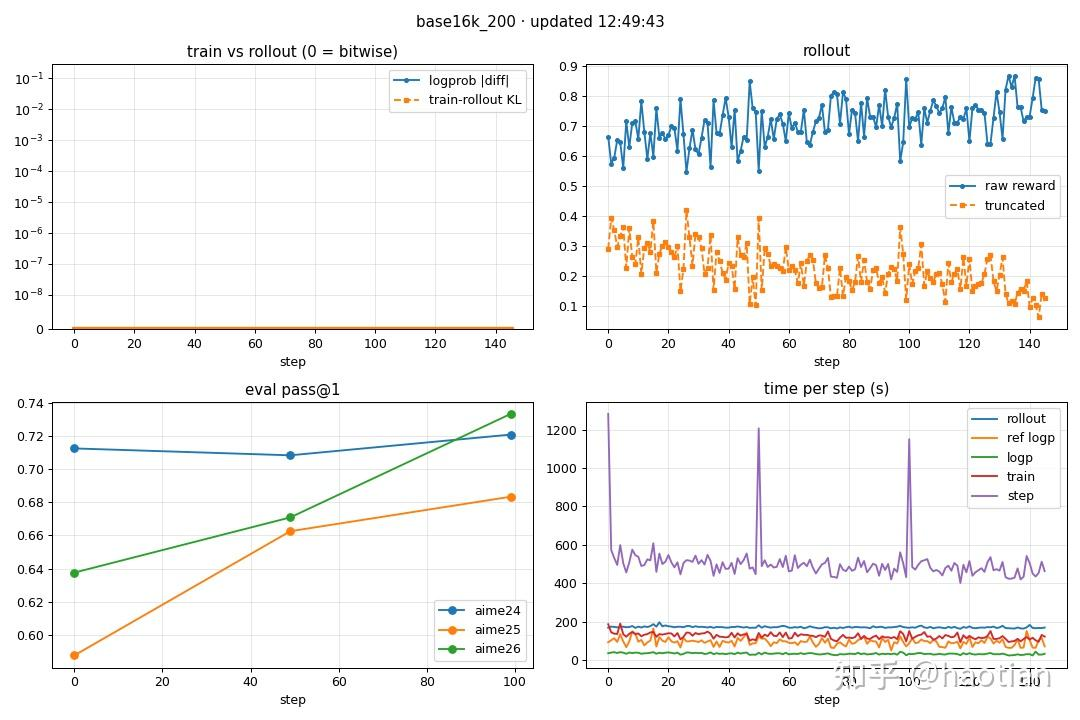

In [14]:
Image(filename='./Image/diff_11.jpg')

四个面板分别是：左上 train/rollout diff（纵轴 log scale，全程贴在 0 上）、右上 rollout reward 与截断率、左下 eval pass@1、右下每步各阶段耗时。

#### 训练正确性：train/rollout diff
全程 146 步 train_rollout_logprob_abs_diff 均为 0，train_rollout_kl 均为 0，无一例外（图左上）。

这是训练端 Megatron forward 和 rollout SGLang decode 的 logprob 差异，两段式方案下始终是 0（逐位相同）。

#### 训练效率（step ≥ 1 平均）

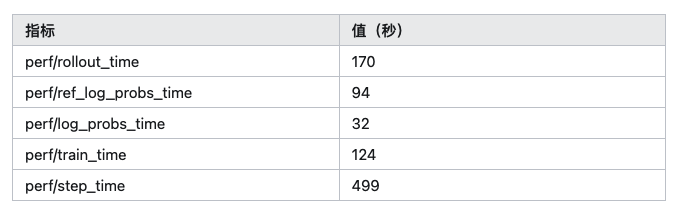

In [15]:
Image(filename='./Image/diff_12.png')

单步约 500 秒（8 卡 colocate，含 rollout、ref、logp、train 全流程）。图右下可见 step 0 以及两次 eval（step 49、99）会出现尖峰，其余步稳定在 450–520 秒区间。

#### 训练效果：reward 与 eval

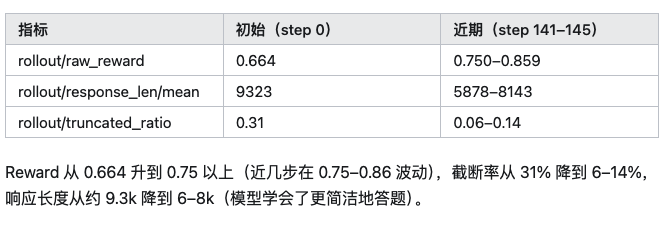

In [16]:
Image(filename='./Image/diff_13.png')

#### Eval（AIME pass@1，deepscaler）：

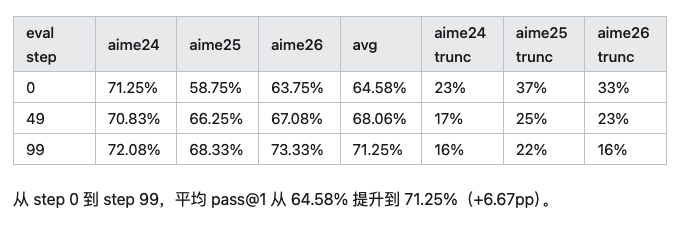

In [17]:
Image(filename='./Image/diff_14.png')

## 实现方式
###  改动点
- SGLang 端：
  - 新增 python/sglang/srt/layers/attention/fla/two_pass.py 两段式 core（pass 1 chunk-parallel + pass 2 recurrent），以及 decode 端的每请求状态存储与同步逻辑。
  - 修改 python/sglang/srt/layers/attention/linear/gdn_backend.py新增开关 SGLANG_GDN_ISO=1，与 SGLANG_GDN_CPR 二选一，同样需要 --disable-radix-cache。
  - 修改 python/sglang/srt/layers/attention/fla/fused_sigmoid_gating_recurrent.py recurrent kernel 的配置可传参，并加了可选的 tail 写入逻辑。Kernel 配置（num_warps=1, BV=16）属于对齐合同的一部分，decode 和训练必须完全一致。


- 训练端（Megatron）：
  - 修改 core/models/qwen3_5/qwen3_5_true_on_policy_autograd.py
  - 新增 DIFF0_GDN_TWO_PASS=1 开关，GDN core 走与 rollout 相同的两段式实现。


- 验证入口：train_vs_decode_iso.py --mode native|cpr|iso
  - 逐位对比 decode vs prefill、prefill vs train、decode vs train 三组 logprob。
- 单元测试：t_state.py
  - 覆盖了按 64 对齐切分的 chunked prefill，以及先 decode、再从非对齐位置接着 extend 的多轮场景（非对齐 extend 会触发 chunked 重算，确保边界状态正确）。
  
### 使用方式
- SGLang rollout 端（decode）：

In [ ]:
export SGLANG_GDN_ISO=1
export SGLANG_GDN_CPR=0  # 确保关闭 CPR
# 启动 sglang.Engine 时必须传 --disable-radix-cache

- Megatron 训练端：

In [ ]:
export DIFF0_GDN_TWO_PASS=1

两端必须 import 到同一份 SGLang（两段式 core 与 recurrent kernel 配置都在 SGLang 侧），否则对齐合同不成立。训练进程通过 SGLANG_PY 指向该 SGLang 的 python 目录。

RL 训练启动时，除上述两个开关外无需额外配置；其余并行度、数据集、eval 间隔等按常规 RL 脚本设置即可。


### 限制
  - 不支持 speculative decoding 和 radix cache（必须 --disable-radix-cache）。
  - Prefill 也走两段式，GDN 部分约慢 4×（短 prompt 任务影响小，长 prompt 多轮任务需注意）。
  - 训练端必须也改为两段式，否则只能对齐到 6.5e-3（和原生 decode 一样差）。
  - 每请求额外显存约 67 MB/槽（4B 模型）。
  
## 与 CPR 方案的对比

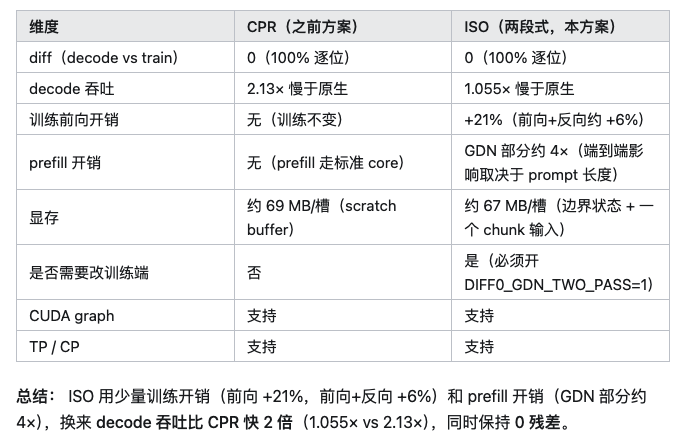

In [18]:
Image(filename='./Image/diff_15.png')

## 与 IsoExec（SkyRL）的对比

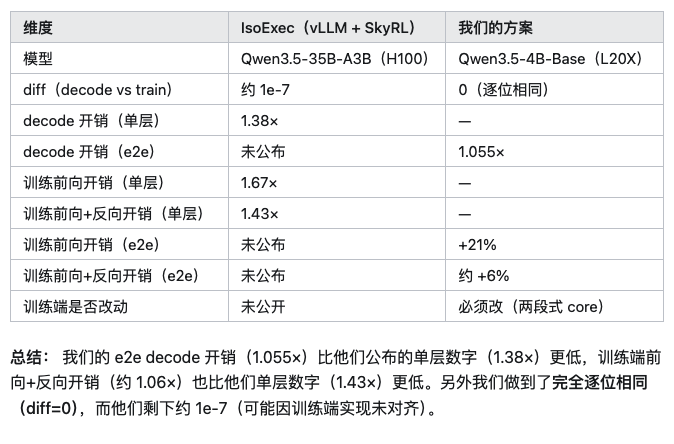

In [19]:
Image(filename='./Image/diff_16.png')

## 参考资料
### 方法论来源：vLLM train-inference-consistency skill
本方案的验证口径（「逐位相同」而非「误差足够小」、diff=0 不能是空读数、按层二分定位不一致）沿用 vLLM 的 train-inference-consistency skill：

  - 上游：vllm-project/vllm#61551
  - 本仓库的再剪裁版本：project/.claude/skills/train-inference-diff0/（把上游的 vLLM batch-invariant inference 换成 sglang-miles fork + Megatron-LM miles_megatron_plugins.true_on_policy，验收指标同为 train_rollout_logprob_abs_diff == 0）

### 两者关系与本方案的定位：

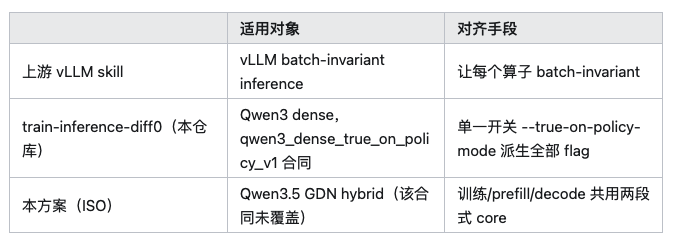

In [20]:
Image(filename='./Image/diff_17.png')

train-inference-diff0 明确只覆盖 qwen3_dense_true_on_policy_v1，GDN hybrid 的线性注意力层不在其中——本方案补的正是这一块。该 skill 中可直接复用的部分：

  - guides/kernel-contract.md：kernel 配置属于对齐合同的一部分（本方案中对应 recurrent kernel 的 num_warps=1, BV=16，decode 与训练必须一致）
  - guides/independent-zero.md：如何判断 diff=0 不是空读数（本方案对应 146 步全 0 且 eval 正常上涨）
  - guides/debugging-mismatch.md：按层二分定位（本方案据此定位到 chunk kernel 把 h/v_new 截断为 bf16）
  - workflow/validation.md、workflow/report-template.md：验证流程与报告口径
  
注意上游 skill 声称的是更强的性质，本仓库合同实现的是其中第一条（见 workflow/report-template.md）。

### IsoExec（SkyRL + vLLM）
博客：https://vllm.ai/blog/2026-08-21-isoexec

第九节对比的方案。其公布的是 H100 上 Qwen3.5-35B-A3B 的单层数字，与我们 L20X 4B 的 e2e 数字不可直接比较。

## 附录：训练 run
base16k_200（146 / 200 步）
  - train_rollout_logprob_abs_diff 全程 0
  - step 99 eval pass@1 平均 71.25%（aime24 72.08%, aime25 68.33%, aime26 73.33%）